# Лабораторная работа 07. Категориальные признаки и точность прогноза цены
**Курс «Анализ данных и искусственный интеллект», 1 курс бакалавриата.**

Создаём инструмент оценки цены для сервиса объявлений о продаже подержанных автомобилей. В ЛР 06 использовали только числа. Теперь добавим марку, модель, кузов, топливо и трансмиссию и проверим, как они меняют прогноз.

**Основная часть:** `.map()` → линейная модель и дерево → OHE → разреженная матрица → Pipeline → Target Encoding → анализ ошибок.

**Бонус:** LightGBM и CatBoost → логарифм цены, Ridge и новые признаки для линейной модели.

Запускайте ячейки сверху вниз. Все примеры кодирования строятся на нашей таблице. После упражнений приведены решения. Модели выбираем по validation; test открываем в конце. Полный запуск бонусов занимает несколько минут, на слабом компьютере — дольше.

## 1. Загружаем данные — как в ЛР 06
Положите рядом тот же `cars_processed.csv`. Если файла нет, загрузим его из репозитория курса. Используем те же четыре числовых признака и те же случайные состояния разбиения.

Если библиотек нет, раскомментируйте установку. После обновления scikit-learn перезапустите ядро. Для `TargetEncoder` нужен scikit-learn не ниже 1.3.

In [1]:
# %pip install "scikit-learn>=1.3" pandas numpy matplotlib scipy lightgbm catboost
from pathlib import Path
from time import perf_counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import sklearn
from sklearn.model_selection import train_test_split, KFold, GridSearchCV, RandomizedSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import StandardScaler, OneHotEncoder, TargetEncoder, FunctionTransformer, SplineTransformer
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.base import clone
from sklearn.inspection import permutation_importance
from scipy import sparse

plt.rcParams.update({'figure.dpi': 110, 'font.size': 11})
pd.set_option('display.max_columns', 30)
print('scikit-learn:', sklearn.__version__)

scikit-learn: 1.8.0


In [2]:
data_path = Path('cars_processed.csv')
if data_path.exists():
    df = pd.read_csv(data_path)
else:
    df = pd.read_csv(
        'https://raw.githubusercontent.com/MVRonkin/BasicDataAnalysisCourse/'
        'refs/heads/main/Workshops/cars_processed.csv'
    )
df = df.rename(columns={'Price(euro)': 'Price', 'Engine_capacity(cm3)': 'Engine'})
technical_columns = [col for col in df if col.startswith('Unnamed:')]
print('Технические индексы, исключаем:', technical_columns)
df = df.drop(columns=technical_columns).reset_index(drop=True)
print('Размер таблицы:', df.shape)
display(df.head())

Технические индексы, исключаем: []
Размер таблицы: (32067, 11)


,Make,Model,Year,Style,Distance,Engine,Fuel_type,AutoTransmission,Price,Age,km_year
0,Toyota,Prius,2011,Hatchback,195000.0,1800.0,Hybrid,True,7750.0,11,17727.272727
1,Renault,Grand Scenic,2014,Universal,135000.0,1500.0,Diesel,False,8550.0,8,16875.000000
2,Renault,Laguna,2012,Universal,110000.0,1500.0,Diesel,False,6550.0,10,11000.000000
3,Opel,Astra,2006,Universal,200000.0,1600.0,Metan/Propan,False,4100.0,16,12500.000000
4,Mercedes,Vito,2000,Microvan,300000.0,2200.0,Diesel,False,3490.0,22,13636.363636


### 1.1. Все исходные столбцы
Сначала рассматриваем весь файл, а затем выбираем признаки. `Price` — ответ, а не вход модели. `Age` и `Year` содержат одну временную характеристику в разных формах: в основной части оставляем `Year`, как в ЛР 06.

В исходном `cars_processed.csv` коробка уже записана как `AutoTransmission`. Для упражнения с `.map()` восстановим текстовые названия. Это обратная запись существующего признака, а не новая информация.

In [3]:
meanings = {
    'Make': 'Марка', 'Model': 'Модель автомобиля', 'Year': 'Год выпуска',
    'Style': 'Тип кузова', 'Distance': 'Пробег, км', 'Engine': 'Объём двигателя, см³',
    'Fuel_type': 'Тип топлива', 'AutoTransmission': 'Автоматическая трансмиссия: True/False',
    'Transmission': 'Тип трансмиссии', 'Price': 'Цена предложения, евро',
    'Age': 'Возраст на дату подготовки набора', 'km_year': 'Расчётный среднегодовой пробег, км'
}
column_overview = pd.DataFrame({
    'Смысл': [meanings.get(col, 'Проверьте назначение этого столбца') for col in df],
    'Тип': df.dtypes.astype(str),
    'Пропуски': df.isna().sum(),
    'Уникальных': df.nunique(dropna=False)
}, index=df.columns)
display(column_overview)

if 'Transmission' not in df:
    transmission_labels = {'true': 'Automatic', 'false': 'Manual',
                           '1': 'Automatic', '0': 'Manual',
                           '1.0': 'Automatic', '0.0': 'Manual'}
    df['Transmission'] = df['AutoTransmission'].astype('string').str.lower().map(transmission_labels)
    assert df['Transmission'].notna().all(), 'Проверьте значения AutoTransmission'
    display(df[['AutoTransmission', 'Transmission']].head())

,Смысл,Тип,Пропуски,Уникальных
Make,Марка,object,0,22
Model,Модель автомобиля,object,0,789
Year,Год выпуска,int64,0,65
Style,Тип кузова,object,0,12
Distance,"Пробег, км",float64,0,8065
Engine,"Объём двигателя, см³",float64,0,602
Fuel_type,Тип топлива,object,0,6
AutoTransmission,Автоматическая трансмиссия: True/False,bool,0,2
Price,"Цена предложения, евро",float64,0,1708
Age,Возраст на дату подготовки набора,int64,0,65


,AutoTransmission,Transmission
0,True,Automatic
1,False,Manual
2,False,Manual
3,False,Manual
4,False,Manual


### 1.2. Выделяем цену и все категории
Число `0/1` у коробки — обозначение категории. Число в `Distance` — измеренная величина. Тип хранения и смысл признака нужно различать.

Используем **все пять исходных категориальных признаков**. `AutoTransmission` повторно не включаем: он дублирует `Transmission`. Не добавляем заранее рассчитанные по всей таблице средние цены групп — это подсказка об ответе.

In [4]:
NUMERIC_FEATURES = ['Year', 'Distance', 'Engine', 'km_year']
CATEGORY_FEATURES = ['Make', 'Model', 'Style', 'Fuel_type', 'Transmission']
FEATURES = NUMERIC_FEATURES + CATEGORY_FEATURES

assert np.isfinite(df[NUMERIC_FEATURES + ['Price']].to_numpy()).all()
assert (df['Price'] > 0).all()
print('Числовые:', NUMERIC_FEATURES)
print('Категориальные:', CATEGORY_FEATURES)
print('Не используем как вход:', [col for col in df if col not in FEATURES])

# Проверка написания; на наших данных не вводим ненужную очистку.
for col in CATEGORY_FEATURES:
    values = df[col].dropna().astype(str)
    print(f'{col}: категорий {values.nunique()}, '
          f'после strip/lower — {values.str.strip().str.lower().nunique()}')

X = df[FEATURES].copy()
y = df['Price'].copy()

Числовые: ['Year', 'Distance', 'Engine', 'km_year']
Категориальные: ['Make', 'Model', 'Style', 'Fuel_type', 'Transmission']
Не используем как вход: ['AutoTransmission', 'Price', 'Age']
Make: категорий 22, после strip/lower — 22
Model: категорий 789, после strip/lower — 789
Style: категорий 12, после strip/lower — 12
Fuel_type: категорий 6, после strip/lower — 6
Transmission: категорий 2, после strip/lower — 2


### 1.3. Те же части 60/20/20
**Train** обучает модели и преобразования. **Validation** сравнивает варианты. **Test** используется в итоговой проверке.

Сохраняем порядок строк и настройки ЛР 06. Если test уже изучали на прошлом занятии, это общий учебный контроль, а не новый независимый эксперимент.

In [5]:
X_train, X_holdout, y_train, y_holdout = train_test_split(
    X, y, test_size=0.4, random_state=42
)
X_valid, X_test, y_valid, y_test = train_test_split(
    X_holdout, y_holdout, test_size=0.5, random_state=43
)
print('Train:', X_train.shape, 'Validation:', X_valid.shape, 'Test:', X_test.shape)
assert set(X_train.index).isdisjoint(X_valid.index)
assert set(X_train.index).isdisjoint(X_test.index)
assert set(X_valid.index).isdisjoint(X_test.index)

Train: (19240, 9) Validation: (6413, 9) Test: (6414, 9)


### Как будем сравнивать
**MAE** — средняя абсолютная ошибка в евро. **RMSE** тоже измеряется в евро, но сильнее реагирует на крупные промахи. **R²** сравнивает сумму квадратов ошибок с прогнозом среднего по оцениваемой части; отрицательный R² означает результат хуже этого ориентира.

Время в таблицах — обучение выбранной конфигурации, без времени поиска гиперпараметров. Небольшая функция только собирает метрики. Само обучение ниже остаётся видимым.

In [6]:
def metrics(actual, predicted):
    return {
        'MAE, евро': mean_absolute_error(actual, predicted),
        'RMSE, евро': np.sqrt(mean_squared_error(actual, predicted)),
        'R²': r2_score(actual, predicted)
    }

validation_rows = []
fitted_models = {}

def evaluate(name, estimator):
    start = perf_counter()
    estimator.fit(X_train, y_train)
    seconds = perf_counter() - start
    prediction = estimator.predict(X_valid)
    row = {'Модель': name, **metrics(y_valid, prediction), 'Обучение, с': seconds}
    validation_rows.append(row)
    fitted_models[name] = estimator
    return row

cv = KFold(n_splits=3, shuffle=True, random_state=42)

## 2. Трансмиссия: `.map()` и линейная регрессия
### 2.1. Значения → словарь → числа
Сначала смотрим реальные значения и их частоты **на train**. Затем явно назначаем коды: `Manual → 0`, `Automatic → 1`.

In [7]:
display(X_train['Transmission'].value_counts(dropna=False).to_frame('Число автомобилей'))
transmission_map = {'Manual': 0, 'Automatic': 1}
transmission_code = X_train['Transmission'].map(transmission_map)
display(pd.DataFrame({
    'Transmission': X_train['Transmission'],
    'Код': transmission_code
}).head(10))
print('Значений без кода:', transmission_code.isna().sum())

Значений без кода: 0


,Число автомобилей
Transmission,
Manual,10443
Automatic,8797


,Transmission,Код
22222,Automatic,1
3091,Automatic,1
24316,Manual,0
22327,Manual,0
13572,Automatic,1
29432,Automatic,1
2178,Automatic,1
3331,Automatic,1
17638,Manual,0
11840,Manual,0


### 2.2. Сравниваем LR с трансмиссией и без неё
Числовые признаки масштабируем. Код трансмиссии оставляем `0/1`: тогда его коэффициент можно прочитать в евро.

`FunctionTransformer` позволяет поместить знакомую операцию `.map()` внутрь Pipeline. Неизвестный тип коробки даст NaN; в этом маленьком бинарном примере заполняем его наиболее частым кодом на train. Далее OHE позволит обрабатывать категории без такого предположения.

In [8]:
def map_transmission(frame):
    return frame['Transmission'].map(transmission_map).to_numpy().reshape(-1, 1)

numeric_processing = Pipeline([
    ('fill', SimpleImputer(strategy='median')),
    ('scale', StandardScaler())
])
map_processing = Pipeline([
    ('map', FunctionTransformer(map_transmission)),
    ('fill', SimpleImputer(strategy='most_frequent'))
])
lr_numeric = Pipeline([
    ('prepare', ColumnTransformer([('num', clone(numeric_processing), NUMERIC_FEATURES)])),
    ('model', LinearRegression())
])
lr_transmission = Pipeline([
    ('prepare', ColumnTransformer([
        ('num', clone(numeric_processing), NUMERIC_FEATURES),
        ('transmission', map_processing, ['Transmission'])
    ])),
    ('model', LinearRegression())
])
evaluate('LR: числа', lr_numeric)
evaluate('LR: числа + map трансмиссии', lr_transmission)
display(pd.DataFrame(validation_rows).set_index('Модель').round(3))

,"MAE, евро","RMSE, евро",R²,"Обучение, с"
Модель,,,,
LR: числа,4307.775,7685.150,0.431,0.015
LR: числа + map трансмиссии,4177.205,7584.741,0.446,0.018


### 2.3. Что означает вес трансмиссии
В прогноз входит слагаемое **вес × код коробки**. Для Manual оно равно нулю, для Automatic — самому весу. Это изменение прогноза при одинаковых остальных признаках. Вес описывает связь, которую нашла модель, а не причинный эффект замены коробки.

In [9]:
weight = lr_transmission.named_steps['model'].coef_[-1]
print(f'Вес Automatic: {weight:+,.0f} евро')

same_car = pd.concat([X_valid.iloc[[0]], X_valid.iloc[[0]]], ignore_index=True)
same_car['Transmission'] = ['Manual', 'Automatic']
same_car['Прогноз, евро'] = lr_transmission.predict(same_car[FEATURES])
display(same_car[['Make', 'Model', 'Year', 'Transmission', 'Прогноз, евро']])
print('Разница прогнозов:', same_car['Прогноз, евро'].diff().iloc[-1])

Вес Automatic: +2,810 евро
Разница прогнозов: 2810.0169047187237


,Make,Model,Year,Transmission,"Прогноз, евро"
0,Renault,Scenic,2010,Manual,7166.247284
1,Renault,Scenic,2010,Automatic,9976.264189


**Проверьте себя.** Что произойдёт с весом и прогнозами, если поменять коды 0 и 1 местами?

**Ответ:** при свободном intercept знак веса изменится и изменится свободный член; прогнозы той же линейной модели сохранятся. Для двух категорий один индикатор достаточен. Для десятков марок ситуация другая.

## 3. Как LR и дерево используют номера категорий
### 3.1. Почему номера марок ограничивают линейную модель
Пронумеруем реальные марки. Если первые три получили коды 0, 1, 2, их вклады в прогноз будут `0`, `w`, `2w`. Получили искусственный порядок и одинаковую разницу между соседними марками. Другие признаки не отменяют этого ограничения именно для вклада марки.

In [10]:
brands = sorted(X_train['Make'].dropna().unique())
brand_map = {brand: code for code, brand in enumerate(brands)}
display(pd.Series(brand_map, name='Код марки').to_frame())
display(X_train[['Make']].head(8).assign(Код=X_train['Make'].map(brand_map).head(8)))

,Код марки
Audi,0
BMW,1
Chevrolet,2
Dacia,3
Ford,4
Honda,5
Hyundai,6
KIA,7
Lexus,8
Mazda,9


,Make,Код
22222,Toyota,18
3091,Volkswagen,20
24316,Mercedes,10
22327,Mazda,9
13572,Skoda,17
29432,Hyundai,6
2178,BMW,1
3331,Volvo,21


### 3.2. Дерево проверяет условия, а не умножает код на общий вес
Условие `код ≤ 0.5` отделяет марку с кодом 0 от остальных. Другое условие может отделить следующую группу. Средняя цена в каждом листе вычисляется независимо: одинакового шага между ценами нет.

Но один порог отделяет только соседние коды. Если похожие марки получили далёкие номера, дереву потребуются дополнительные разбиения. Поэтому RF может работать с номерами категорий, но их порядок не безразличен.

Сначала показываем `.map()` для всех категорий. Словари строим только по train; новую категорию обозначаем −1.

In [11]:
category_maps = {
    col: {value: i for i, value in enumerate(sorted(X_train[col].dropna().unique()))}
    for col in CATEGORY_FEATURES
}

def encode_with_maps(frame, maps):
    result = frame[NUMERIC_FEATURES].copy()
    for col in CATEGORY_FEATURES:
        result[col] = frame[col].map(maps[col]).fillna(-1).astype(int)
    return result

codes_train = encode_with_maps(X_train, category_maps)
codes_valid = encode_with_maps(X_valid, category_maps)
display(X_train[CATEGORY_FEATURES].head())
display(codes_train[CATEGORY_FEATURES].head())

,Make,Model,Style,Fuel_type,Transmission
22222,Toyota,Corolla,Hatchback,Diesel,Automatic
3091,Volkswagen,Golf,Hatchback,Petrol,Automatic
24316,Mercedes,Vito,Minivan,Diesel,Manual
22327,Mazda,626,Sedan,Petrol,Manual
13572,Skoda,Superb,Sedan,Diesel,Automatic


,Make,Model,Style,Fuel_type,Transmission
22222,18,222,4,0,0
3091,20,325,4,4,0
24316,10,678,6,0,1
22327,9,75,10,4,1
13572,17,620,10,0,0


### 3.3. Дерево глубины 3
В каждом узле показаны условие, число обучающих строк и средняя цена. Найдите узлы с категориями; расшифруйте порог по словарю. Категория может не войти в такое маленькое дерево — это не доказательство её бесполезности.

Узел 1: Transmission ≤ 0.5; налево из известных категорий: ['Automatic']


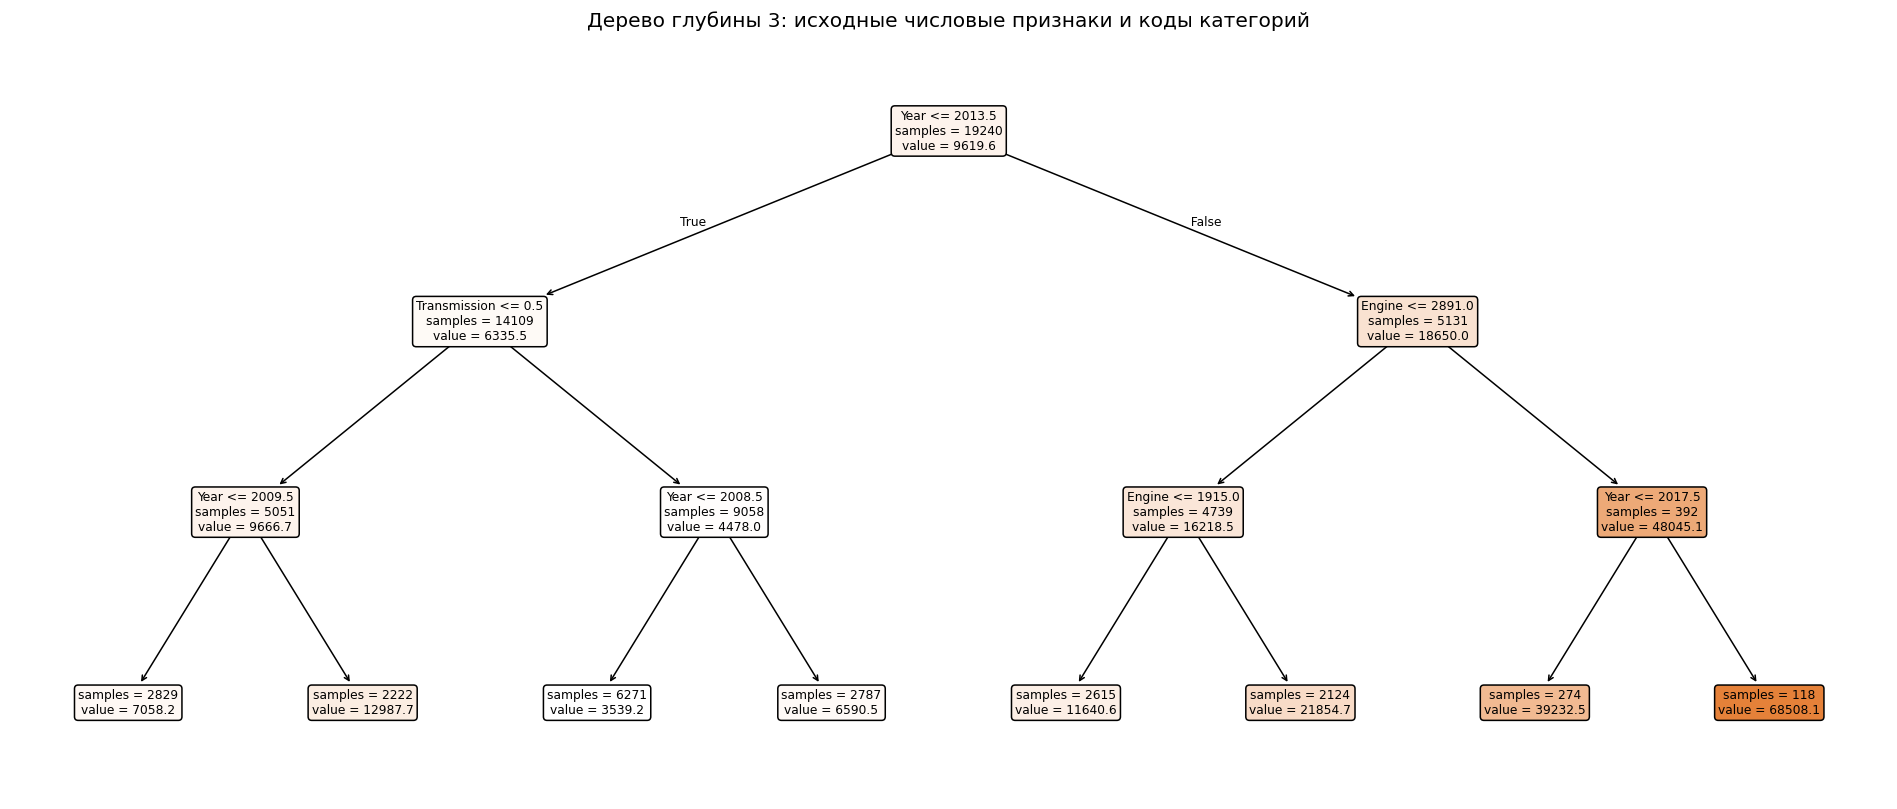

In [12]:
small_tree = DecisionTreeRegressor(max_depth=3, min_samples_leaf=40, random_state=42)
small_tree.fit(codes_train, y_train)
fig, ax = plt.subplots(figsize=(22, 9))
plot_tree(small_tree, feature_names=codes_train.columns.tolist(),
          filled=True, rounded=True, impurity=False, precision=1, fontsize=8, ax=ax)
ax.set_title('Дерево глубины 3: исходные числовые признаки и коды категорий')
plt.show()

for node, feature in enumerate(small_tree.tree_.feature):
    if feature >= 0:
        col = codes_train.columns[feature]
        if col in CATEGORY_FEATURES:
            threshold = small_tree.tree_.threshold[node]
            left = [value for value, code in category_maps[col].items() if code <= threshold]
            print(f'Узел {node}: {col} ≤ {threshold:.1f}; налево из известных категорий:', left)

### 3.4. Меняем порядок кодов: эксперимент с LR и RF
Обучаем модели на одинаковых строках с двумя порядками кодов. В RF меняется только порядок кодов: случайное состояние и параметры леса фиксированы. Направление изменения ошибки заранее не задаём.

In [13]:
rng = np.random.default_rng(42)
shuffled_maps = {
    col: dict(zip(mapping.keys(), rng.permutation(len(mapping))))
    for col, mapping in category_maps.items()
}
code_comparison = []
for order, maps in [('Исходный порядок', category_maps), ('Перемешанные коды', shuffled_maps)]:
    a = encode_with_maps(X_train, maps)
    b = encode_with_maps(X_valid, maps)
    candidates = {
        'LR': Pipeline([('scale', StandardScaler()), ('model', LinearRegression())]),
        'RF': RandomForestRegressor(n_estimators=80, max_depth=16, min_samples_leaf=3,
                                    n_jobs=2, random_state=42)
    }
    for name, model in candidates.items():
        model.fit(a, y_train)
        code_comparison.append({'Модель': name, 'Коды': order,
                                **metrics(y_valid, model.predict(b))})
display(pd.DataFrame(code_comparison).round(3))

,Модель,Коды,"MAE, евро","RMSE, евро",R²
0,LR,Исходный порядок,4168.695,7583.469,0.446
1,RF,Исходный порядок,2024.415,5027.278,0.756
2,LR,Перемешанные коды,4134.847,7551.608,0.450
3,RF,Перемешанные коды,2027.861,5007.839,0.758


## 4. One-hot encoding: отдельный индикатор для каждого значения
### 4.1. Сколько у нас категорий?
OHE заменяет один категориальный столбец несколькими столбцами 0/1. У индикаторов нет искусственного порядка; линейная модель может назначить каждому свой вес. Посмотрим масштаб задачи **для всех наших категориальных признаков**.

In [14]:
category_sizes = pd.DataFrame({
    'Категорий на train': X_train[CATEGORY_FEATURES].nunique(),
    'Значений с частотой < 20': [
        (X_train[col].value_counts() < 20).sum() for col in CATEGORY_FEATURES
    ],
    'Пропусков': X_train[CATEGORY_FEATURES].isna().sum()
})
display(category_sizes)
print('Столбцов OHE без объединения:', category_sizes['Категорий на train'].sum())
for col in CATEGORY_FEATURES:
    print(col)
    display(X_train[col].value_counts().head(6).to_frame('Число строк'))

Столбцов OHE без объединения: 765
Make
Model
Style
Fuel_type
Transmission


,Категорий на train,Значений с частотой < 20,Пропусков
Make,22,0,0
Model,723,553,0
Style,12,1,0
Fuel_type,6,1,0
Transmission,2,0,0


,Число строк
Make,
Volkswagen,2039
Toyota,1833
Mercedes,1786
Rare,1549
BMW,1540
Renault,1432


,Число строк
Model,
E Class,669
5 Series,614
Passat,511
Megane,489
Golf,470
Astra,452


,Число строк
Style,
Sedan,5880
Universal,3458
Hatchback,3113
Crossover,2421
SUV,1859
Minivan,1555


,Число строк
Fuel_type,
Diesel,9101
Petrol,6726
Metan/Propan,2067
Hybrid,1065
Plug-in Hybrid,265
Electric,16


,Число строк
Transmission,
Manual,10443
Automatic,8797


### 4.2. OHE на реальных строках
Для первого просмотра берём несколько реальных объявлений и все пять категорий. `pd.get_dummies` удобно показывает смысл преобразования. Для модели далее используем обучаемый `OneHotEncoder`, чтобы train и test имели одни и те же столбцы.

In [15]:
real_rows = X_train[CATEGORY_FEATURES].head(6)
display(real_rows)
display(pd.get_dummies(real_rows, dtype=int))

,Make,Model,Style,Fuel_type,Transmission
22222,Toyota,Corolla,Hatchback,Diesel,Automatic
3091,Volkswagen,Golf,Hatchback,Petrol,Automatic
24316,Mercedes,Vito,Minivan,Diesel,Manual
22327,Mazda,626,Sedan,Petrol,Manual
13572,Skoda,Superb,Sedan,Diesel,Automatic
29432,Hyundai,Terracan,Hatchback,Metan/Propan,Automatic


,Make_Hyundai,Make_Mazda,Make_Mercedes,Make_Skoda,Make_Toyota,Make_Volkswagen,Model_626,Model_Corolla,Model_Golf,Model_Superb,Model_Terracan,Model_Vito,Style_Hatchback,Style_Minivan,Style_Sedan,Fuel_type_Diesel,Fuel_type_Metan/Propan,Fuel_type_Petrol,Transmission_Automatic,Transmission_Manual
22222,0,0,0,0,1,0,0,1,0,0,0,0,1,0,0,1,0,0,1,0
3091,0,0,0,0,0,1,0,0,1,0,0,0,1,0,0,0,0,1,1,0
24316,0,0,1,0,0,0,0,0,0,0,0,1,0,1,0,1,0,0,0,1
22327,0,1,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,1,0,1
13572,0,0,0,1,0,0,0,0,0,1,0,0,0,0,1,1,0,0,1,0
29432,1,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,1,0,1,0


### 4.3. Редкие категории
У модели автомобиля, представленной двумя объявлениями, мало данных для оценки собственного эффекта. Объединим редкие значения в «Другие». Порог 20 — учебная настройка, которую ниже проверим экспериментом.

Здесь показываем операцию вручную. В Pipeline ту же идею реализует `OneHotEncoder(min_frequency=20)`, чтобы частоты пересчитывались внутри каждого обучающего разбиения.

In [16]:
model_counts = X_train['Model'].value_counts()
frequent_models = model_counts[model_counts >= 20].index
model_before_after = X_train[['Model']].copy()
model_before_after['После объединения'] = X_train['Model'].where(
    X_train['Model'].isin(frequent_models), 'Другие'
)
display(model_before_after.loc[~X_train['Model'].isin(frequent_models)].head(10))
print('До:', X_train['Model'].nunique())
print('После:', model_before_after['После объединения'].nunique())

До: 723
После: 171


,Model,После объединения
29432,Terracan,Другие
21100,Frontera,Другие
28443,SX4,Другие
29578,469,Другие
7654,ASX,Другие
31463,NV200,Другие
11887,Bora,Другие
18308,iQ,Другие
15461,Space Wagon,Другие
24180,Carisma,Другие


### 4.4. OneHotEncoder: fit на train, transform остальных частей
`fit` запоминает категории и редкие значения. `transform` применяет готовую схему. `handle_unknown='infrequent_if_exist'` отправляет новое значение в группу редких, если такая группа обучена; иначе его блок индикаторов будет нулевым.

Пропуск, редкая категория и новая категория — разные ситуации. Пропуск сначала обозначаем строкой `Пропуск`. При заданном пороге этот маркер тоже может попасть в редкую группу.

In [17]:
category_fill = SimpleImputer(strategy='constant', fill_value='Пропуск')
cat_train = category_fill.fit_transform(X_train[CATEGORY_FEATURES])
cat_valid = category_fill.transform(X_valid[CATEGORY_FEATURES])
encoder = OneHotEncoder(min_frequency=20, handle_unknown='infrequent_if_exist',
                        sparse_output=True)
encoded_train = encoder.fit_transform(cat_train)
encoded_valid = encoder.transform(cat_valid)
encoded_names = encoder.get_feature_names_out(CATEGORY_FEATURES)
print('Train:', encoded_train.shape, 'Validation:', encoded_valid.shape)
print('Примеры названий:', encoded_names[:15])

# Для просмотра выбираем только активные столбцы первых шести реальных строк.
active = np.asarray(encoded_train[:6].sum(axis=0)).ravel() > 0
display(pd.DataFrame(encoded_train[:6, active].toarray(),
                     columns=encoded_names[active], index=X_train.index[:6]))

Train: (19240, 213) Validation: (6413, 213)
Примеры названий: ['Make_Audi' 'Make_BMW' 'Make_Chevrolet' 'Make_Dacia' 'Make_Ford'
 'Make_Honda' 'Make_Hyundai' 'Make_KIA' 'Make_Lexus' 'Make_Mazda'
 'Make_Mercedes' 'Make_Mitsubishi' 'Make_Nissan' 'Make_Opel'
 'Make_Peugeot']


,Make_Hyundai,Make_Mazda,Make_Mercedes,Make_Skoda,Make_Toyota,Make_Volkswagen,Model_626,Model_Corolla,Model_Golf,Model_Superb,Model_Vito,Model_infrequent_sklearn,Style_Hatchback,Style_Minivan,Style_Sedan,Fuel_type_Diesel,Fuel_type_Metan/Propan,Fuel_type_Petrol,Transmission_Automatic,Transmission_Manual
22222,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
3091,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0
24316,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0
22327,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0
13572,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0
29432,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0


In [18]:
unknown_counts = pd.Series({
    col: (~X_valid[col].isin(X_train[col].dropna().unique()) & X_valid[col].notna()).sum()
    for col in CATEGORY_FEATURES
}, name='Строк validation с новой категорией')
display(unknown_counts.to_frame())

# Искусственно меняем одно значение настоящей строки — только для проверки поведения.
new_car = X_valid[CATEGORY_FEATURES].iloc[[0]].copy()
new_car['Model'] = 'Модель, которой нет в train'
new_encoded = encoder.transform(category_fill.transform(new_car))
print('Размер новой строки:', new_encoded.shape)
print('Активные индикаторы:', encoded_names[new_encoded.indices].tolist())

Размер новой строки: (1, 213)
Активные индикаторы: ['Make_Renault', 'Model_infrequent_sklearn', 'Style_Hatchback', 'Fuel_type_Diesel', 'Transmission_Manual']


,Строк validation с новой категорией
Make,0
Model,38
Style,0
Fuel_type,0
Transmission,0


## 5. Sparse: зачем хранить нули?
Каждое объявление активирует лишь несколько индикаторов. Разреженная матрица хранит значения ненулевых элементов, их позиции и служебные указатели. Прогноз использует те же значения, что и плотная матрица.

`shape` — размер; `nnz` — число ненулевых элементов. `.toarray()` создаёт плотный массив: используем его только для небольшого фрагмента.

In [19]:
csr = encoded_train.tocsr()
sparse_bytes = csr.data.nbytes + csr.indices.nbytes + csr.indptr.nbytes
dense_bytes = csr.shape[0] * csr.shape[1] * csr.dtype.itemsize
print('Формат:', type(csr).__name__)
print('Размер:', csr.shape, 'ненулевых элементов:', csr.nnz)
print(f'Ненулевых: {100 * csr.nnz / np.prod(csr.shape):.2f}%')
print(f'Sparse: {sparse_bytes / 1024**2:.2f} МБ')
print(f'Плотный массив занял бы: {dense_bytes / 1024**2:.2f} МБ')
print('Фрагмент 4 × 12:')
print(csr[:4, :12].toarray())

Формат: csr_matrix
Размер: (19240, 213) ненулевых элементов: 96200
Ненулевых: 2.35%
Sparse: 1.17 МБ
Плотный массив занял бы: 31.27 МБ
Фрагмент 4 × 12:
[[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0.]]


## 6. ColumnTransformer и Pipeline: используем все признаки
Числовая ветка заполняет пропуски медианами train и масштабирует значения. Категориальная заполняет пропуски и применяет OHE. `ColumnTransformer` объединяет результаты, а `Pipeline` передаёт их модели.

`remainder='drop'` означает: используются ровно перечисленные столбцы. `sparse_threshold=1.0` сохраняет разреженное объединение, когда в нём есть нули. Деревьям масштабирование не нужно, но оно не меняет порядок значений; здесь сохраняем одну схему обработки для сравнения.

In [20]:
categorical_processing = Pipeline([
    ('fill', SimpleImputer(strategy='constant', fill_value='Пропуск')),
    ('encode', OneHotEncoder(min_frequency=20, handle_unknown='infrequent_if_exist',
                             sparse_output=True))
])
preprocessor = ColumnTransformer([
    ('num', clone(numeric_processing), NUMERIC_FEATURES),
    ('cat', categorical_processing, CATEGORY_FEATURES)
], remainder='drop', sparse_threshold=1.0)

prepared_train = preprocessor.fit_transform(X_train, y_train)
prepared_valid = preprocessor.transform(X_valid)
print('После объединения:', prepared_train.shape, prepared_valid.shape)
print('Разреженная:', sparse.issparse(prepared_train))
print('Числовые и первые категориальные имена:', preprocessor.get_feature_names_out()[:16])

После объединения: (19240, 217) (6413, 217)
Разреженная: True
Числовые и первые категориальные имена: ['num__Year' 'num__Distance' 'num__Engine' 'num__km_year' 'cat__Make_Audi'
 'cat__Make_BMW' 'cat__Make_Chevrolet' 'cat__Make_Dacia' 'cat__Make_Ford'
 'cat__Make_Honda' 'cat__Make_Hyundai' 'cat__Make_KIA' 'cat__Make_Lexus'
 'cat__Make_Mazda' 'cat__Make_Mercedes' 'cat__Make_Mitsubishi']


### 6.1. LR и RF: только числа или числа + категории
Создаём новую копию преобразований для каждой модели. Вызов `Pipeline.fit` обучит преобразования заново, только по переданным обучающим строкам.

In [21]:
lr_ohe = Pipeline([('prepare', clone(preprocessor)), ('model', LinearRegression())])
rf_numeric = Pipeline([
    ('prepare', ColumnTransformer([('num', clone(numeric_processing), NUMERIC_FEATURES)])),
    ('model', RandomForestRegressor(n_estimators=80, max_depth=16, min_samples_leaf=3,
                                    random_state=42, n_jobs=2))
])
rf_ohe = Pipeline([
    ('prepare', clone(preprocessor)),
    ('model', RandomForestRegressor(n_estimators=80, max_depth=16, min_samples_leaf=3,
                                    random_state=42, n_jobs=2))
])
evaluate('LR: OHE', lr_ohe)
evaluate('RF: числа', rf_numeric)
evaluate('RF: OHE', rf_ohe)
display(pd.DataFrame(validation_rows).set_index('Модель').round(3))

,"MAE, евро","RMSE, евро",R²,"Обучение, с"
Модель,,,,
LR: числа,4307.775,7685.150,0.431,0.015
LR: числа + map трансмиссии,4177.205,7584.741,0.446,0.018
LR: OHE,3543.912,6851.410,0.548,0.117
RF: числа,2684.941,5722.625,0.684,1.394
RF: OHE,2037.646,5047.769,0.754,12.356


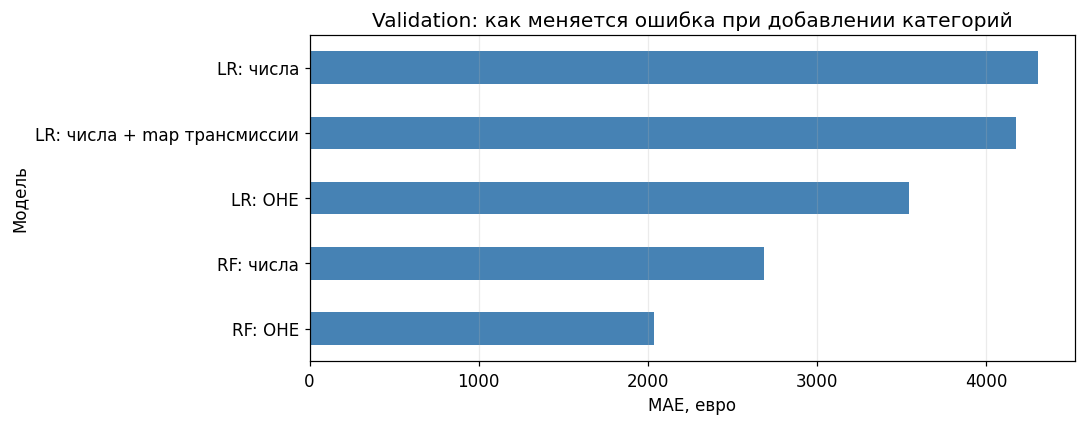

,Make,Model,Year,Transmission,Цена,LR: числа,LR: OHE,RF: OHE
10010,Renault,Scenic,2010,Manual,4850.0,8217.0,5404.0,5051.0
17872,Mazda,Xedos,1995,Manual,1000.0,-4162.0,-4937.0,1778.0
18353,Rare,Ibiza,2011,Manual,4850.0,6929.0,5448.0,5055.0
29466,Mazda,323,1996,Manual,1100.0,1332.0,3576.0,1661.0
19638,Volkswagen,Passat,1998,Manual,2000.0,76.0,659.0,2180.0
11933,Nissan,Sunny,1995,Manual,2150.0,27.0,-207.0,1969.0


In [22]:
comparison = pd.DataFrame(validation_rows).set_index('Модель')
fig, ax = plt.subplots(figsize=(10, 4))
comparison['MAE, евро'].sort_values().plot.barh(ax=ax, color='steelblue')
ax.set(title='Validation: как меняется ошибка при добавлении категорий', xlabel='MAE, евро')
ax.grid(axis='x', alpha=.25)
plt.tight_layout()
plt.show()

examples = X_valid[['Make', 'Model', 'Year', 'Transmission']].head(6).copy()
examples['Цена'] = y_valid.head(6)
examples['LR: числа'] = lr_numeric.predict(X_valid.head(6))
examples['LR: OHE'] = lr_ohe.predict(X_valid.head(6))
examples['RF: OHE'] = rf_ohe.predict(X_valid.head(6))
display(examples.round(0))

### 6.2. Упражнение: выбираем порог редкости
**Задание.** Сравните отсутствие объединения и пороги 5, 20, 100. Для каждого варианта получите число признаков, MAE по трём внутренним разбиениям train и время обучения. Используйте одну модель — Ridge с фиксированным `alpha=10`.

**Решение ниже.** В каждом разбиении обучаем **весь Pipeline**: категории не должны быть определены заранее по будущей валидационной части. Количество признаков может различаться между разбиениями; показываем среднее.

In [23]:
rare_rows = []
for threshold in [None, 5, 20, 100]:
    fold_mae, fold_width, fold_seconds = [], [], []
    for fit_idx, check_idx in cv.split(X_train):
        candidate = Pipeline([
            ('prepare', clone(preprocessor)),
            ('model', Ridge(alpha=10, solver='lsqr'))
        ])
        candidate.set_params(prepare__cat__encode__min_frequency=threshold)
        start = perf_counter()
        candidate.fit(X_train.iloc[fit_idx], y_train.iloc[fit_idx])
        fold_seconds.append(perf_counter() - start)
        pred = candidate.predict(X_train.iloc[check_idx])
        fold_mae.append(mean_absolute_error(y_train.iloc[check_idx], pred))
        fold_width.append(len(candidate.named_steps['prepare'].get_feature_names_out()))
    rare_rows.append({
        'Порог': 'Без объединения' if threshold is None else str(threshold),
        'Признаков, среднее': np.mean(fold_width), 'CV MAE, евро': np.mean(fold_mae),
        'CV MAE std': np.std(fold_mae), 'Обучение фолда, с': np.mean(fold_seconds)
    })
rare_results = pd.DataFrame(rare_rows)
display(rare_results.round(2))
print('Лучший порог по CV:', rare_results.loc[rare_results['CV MAE, евро'].idxmin(), 'Порог'])

Лучший порог по CV: Без объединения


,Порог,"Признаков, среднее","CV MAE, евро",CV MAE std,"Обучение фолда, с"
0,Без объединения,715.00,3385.52,43.67,0.05
1,5,389.67,3435.92,37.21,0.08
2,20,179.67,3623.73,50.45,0.07
3,100,75.67,3833.46,68.59,0.07


**Интерпретация.** Сравните сокращение числа признаков с изменением MAE. Сильное объединение может удалить полезные различия между моделями автомобилей. Минимальное изменение MAE на одном разбиении ещё не доказывает превосходство настройки. В дальнейших базовых сравнениях сохраняем единый учебный порог 20.

## 7. Другие категории и Target Encoding
Номинальные категории (`Make`, `Fuel_type`) не имеют числового порядка. Для действительно порядковых категорий — например, уровней состояния «плохое / среднее / хорошее» — можно задать порядок явно, но равенство расстояний между уровнями всё равно требует осторожности. В нашей таблице такого столбца нет.

**Frequency encoding** заменяет категорию её частотой: это распространённость, а не средняя цена. **Target Encoding** использует целевую переменную: заменяет категорию оценкой средней цены. Он особенно удобен для столбцов с большим числом значений.

### 7.1. Средняя цена категории и сглаживание
Возьмём настоящие марки. Сглаженная оценка — смесь средней цены марки и общей средней:

$$code_g = \frac{n_g\overline y_g + m\overline y}{n_g + m}.$$

При маленьком числе примеров $n_g$ сильнее влияние общей средней. `m=20` — сила сглаживания в этом примере. Высокий код означает высокую среднюю цену, **а не высокую важность признака**.

In [24]:
train_table = X_train.assign(Price=y_train)
make_target_table = train_table.groupby('Make')['Price'].agg(['size', 'mean'])
global_mean = y_train.mean()
m_smooth = 20
make_target_table['Сглаженный код'] = (
    make_target_table['size'] * make_target_table['mean'] + m_smooth * global_mean
) / (make_target_table['size'] + m_smooth)
display(make_target_table.sort_values('size').round(1))

,size,mean,Сглаженный код
Make,,,
Chevrolet,201,7329.1,7536.4
Peugeot,219,4712.4,5123.0
Mazda,249,5235.0,5561.0
Vaz,291,3752.5,4129.8
Lexus,336,18209.2,17726.6
Volvo,344,15725.0,15389.5
Mitsubishi,365,7297.4,7418.0
KIA,383,13353.8,13168.5
Honda,541,9211.6,9226.2


### 7.2. Почему нельзя просто подставить среднюю цену по всей таблице
Если у категории одна строка, её несглаженная средняя совпадает с ответом этой строки. Даже если test исключён, собственная цена строки может попасть в её обучающий признак.

`TargetEncoder.fit_transform(X_train, y_train)` использует внутренние разбиения: код для каждой части train рассчитывается по другим частям. Для validation и test метод `transform` использует статистики всего train.

**Важно:** `fit(X_train, y_train).transform(X_train)` не равно `fit_transform(X_train, y_train)`. Для обучения модели используем второй вариант. В Pipeline это происходит автоматически.

In [25]:
target_encoder = TargetEncoder(target_type='continuous', smooth=20,
                               cv=5, shuffle=True, random_state=42)
te_train = target_encoder.fit_transform(X_train[CATEGORY_FEATURES], y_train)
te_valid = target_encoder.transform(X_valid[CATEGORY_FEATURES])
print('Размер после Target Encoding:', te_train.shape)
display(pd.DataFrame(te_train[:8], columns=CATEGORY_FEATURES, index=X_train.index[:8]).round(1))

# Два способа получить код той же обучающей строки — только для объяснения утечки.
model_position = CATEGORY_FEATURES.index('Model')
show_idx = np.argsort(X_train['Model'].map(X_train['Model'].value_counts()).to_numpy())[:8]
leak_demo = X_train.iloc[show_idx][['Make', 'Model']].copy()
leak_demo['Цена'] = y_train.iloc[show_idx]
leak_demo['Код без собственной части'] = te_train[show_idx, model_position]
leak_demo['Код с собственной ценой'] = target_encoder.transform(
    X_train.iloc[show_idx][CATEGORY_FEATURES])[:, model_position]
display(leak_demo.round(1))

Размер после Target Encoding: (19240, 5)


,Make,Model,Style,Fuel_type,Transmission
22222,9770.4,6293.9,5904.2,10475.5,14820.0
3091,6973.5,5866.4,5848.6,8582.9,14814.4
24316,13329.9,8124.1,6487.7,10510.7,5242.5
22327,5714.7,4612.3,9088.5,8573.5,5191.7
13572,9029.5,13047.6,9049.0,10510.7,14814.4
29432,12302.0,9347.5,5864.5,5391.2,14776.8
2178,13975.6,18519.0,6620.4,8573.5,14820.0
3331,15416.8,16312.8,17510.0,10536.7,14827.6


,Make,Model,Цена,Код без собственной части,Код с собственной ценой
21440,Rare,Trooper,1500.0,9662.6,9233.0
20556,Rare,Bravo,2400.0,9636.5,9275.8
6969,Rare,Magnum,6699.0,9606.3,9480.5
2038,Ford,Focus Rs,12999.0,9636.5,9780.5
19729,Chevrolet,Lumina,2800.0,9662.6,9294.9
21695,Rare,Prisma,700.0,9636.5,9194.9
22382,Opel,Karl,3350.0,9589.8,9321.1
25032,Opel,Sintra,1400.0,9662.6,9228.2


### 7.3. OHE против Target Encoding
Заменяем только категориальную ветку. В LR числовые значения target-кодов масштабируем по обучающей части. Важное отличие: OHE сохраняет отдельные индикаторы, TE сжимает каждый исходный категориальный столбец в один числовой признак.

In [26]:
te_preprocessor = ColumnTransformer([
    ('num', clone(numeric_processing), NUMERIC_FEATURES),
    ('cat', Pipeline([
        ('encode', TargetEncoder(target_type='continuous', smooth=20, cv=5,
                                  shuffle=True, random_state=42)),
        ('scale', StandardScaler())
    ]), CATEGORY_FEATURES)
])
lr_te = Pipeline([('prepare', clone(te_preprocessor)), ('model', LinearRegression())])
rf_te = Pipeline([
    ('prepare', clone(te_preprocessor)),
    ('model', RandomForestRegressor(n_estimators=80, max_depth=16, min_samples_leaf=3,
                                    random_state=42, n_jobs=2))
])
evaluate('LR: Target Encoding', lr_te)
evaluate('RF: Target Encoding', rf_te)
encoding_comparison = pd.DataFrame(validation_rows).set_index('Модель').loc[
    ['LR: OHE', 'LR: Target Encoding', 'RF: OHE', 'RF: Target Encoding']].copy()
encoding_comparison['Признаков'] = [
    fitted_models[name].named_steps['prepare'].transform(X_valid.iloc[:1]).shape[1]
    for name in encoding_comparison.index
]
display(encoding_comparison.round(3))

,"MAE, евро","RMSE, евро",R²,"Обучение, с",Признаков
Модель,,,,,
LR: OHE,3543.912,6851.410,0.548,0.117,217
LR: Target Encoding,3782.384,7011.329,0.526,0.039,9
RF: OHE,2037.646,5047.769,0.754,12.356,217
RF: Target Encoding,1942.872,4879.855,0.771,2.840,9


### Минусы Target Encoding — что проверять
- **Утечка:** код обучающей строки не должен использовать её собственный ответ. Внешняя валидация модели и внутренние разбиения энкодера решают разные задачи.
- **Редкие значения:** средние нестабильны; нужны сглаживание и проверка качества.
- **Потеря различий:** две категории с одинаковой средней могут иметь разные разбросы и разные зависимости цены от возраста. Один код это не передаёт.
- **Новые категории:** получают общую среднюю, потому что данных о них нет. Пропуск TargetEncoder рассматривает как категорию.
- **Сдвиг данных:** средние на старых объявлениях могут не соответствовать новому рынку.

Выбирать TE только из-за меньшего числа столбцов нельзя: сравниваем ошибку на отложенных данных.

## 8. Какие исходные признаки использует модель?
Перемешиваем **один исходный столбец** validation, затем получаем прогноз через весь обученный Pipeline. Если MAE увеличилась, модель использовала информацию этого столбца.

При `scoring='neg_mean_absolute_error'` положительная важность равна увеличению MAE в евро. Коррелирующие признаки могут заменять друг друга; это не причинный эффект и не полный вклад признака в реальном мире.

,"Рост MAE, евро",Разброс повторов
Transmission,215.2,5.8
Distance,237.3,4.8
km_year,239.3,7.6
Style,250.2,15.9
Fuel_type,297.2,18.5
Make,502.9,12.9
Model,1329.3,10.1
Engine,1621.7,47.2
Year,4428.8,14.3


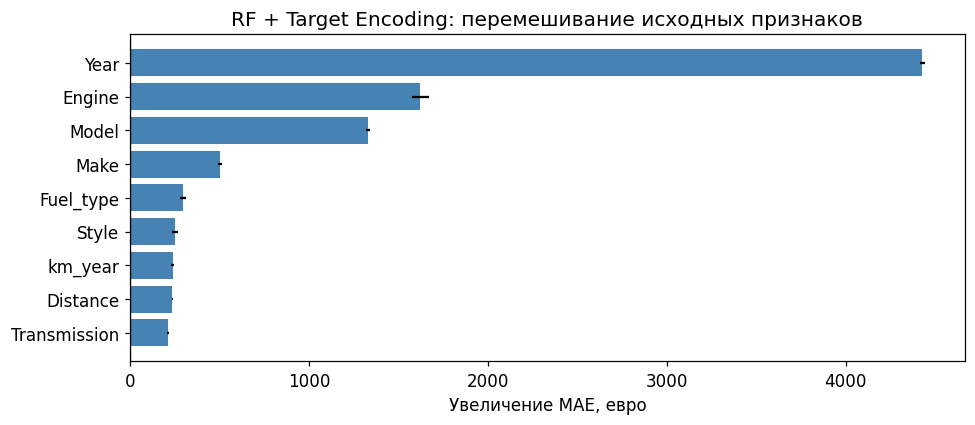

In [27]:
importance = permutation_importance(
    rf_te, X_valid, y_valid, scoring='neg_mean_absolute_error',
    n_repeats=3, random_state=42, n_jobs=1, max_samples=min(2000, len(X_valid))
)
importance_table = pd.DataFrame({
    'Рост MAE, евро': importance.importances_mean,
    'Разброс повторов': importance.importances_std
}, index=X_valid.columns).sort_values('Рост MAE, евро')
display(importance_table.round(1))
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(importance_table.index, importance_table['Рост MAE, евро'],
        xerr=importance_table['Разброс повторов'], color='steelblue')
ax.axvline(0, color='black', linewidth=.8)
ax.set(title='RF + Target Encoding: перемешивание исходных признаков', xlabel='Увеличение MAE, евро')
plt.tight_layout()
plt.show()

## 9. Анализ ошибок: где модель промахивается?
### 9.1. Факт, прогноз и остатки
Возьмём лучший из четырёх вариантов OHE/TE по validation. Остаток определим как **фактическая цена − прогноз**: положительный остаток означает недооценку автомобиля.

Анализируем: RF: Target Encoding


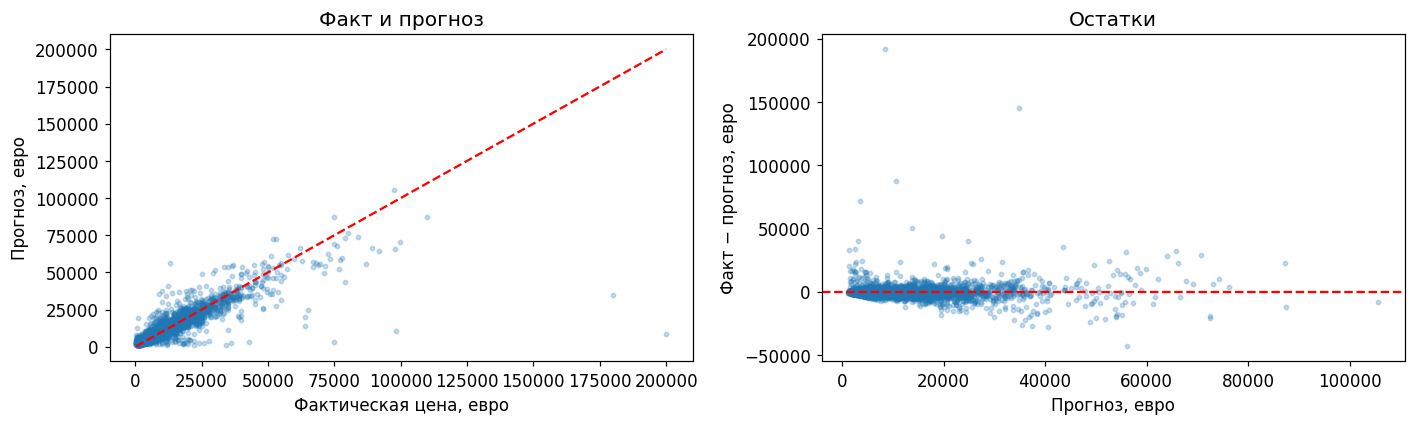

,Year,Distance,Engine,km_year,Make,Model,Style,Fuel_type,Transmission,Цена,Прогноз,Остаток,Абсолютная ошибка
13114,2015,158260.0,1395.0,22609.0,Volkswagen,Caddy,Combi,Metan/Propan,Manual,200000.0,8496.0,191504.0,191504.0
23130,2016,20000.0,3800.0,3333.0,Rare,Altele,Coupe,Petrol,Automatic,179999.0,34817.0,145182.0,145182.0
24172,2011,12609.0,2000.0,1146.0,Mitsubishi,Pajero Sport,SUV,Metan/Propan,Automatic,98050.0,10545.0,87505.0,87505.0
13609,2002,455000.0,1897.0,22750.0,Volkswagen,Sharan,Minivan,Diesel,Manual,75000.0,3450.0,71550.0,71550.0
15869,2017,44000.0,1499.0,8800.0,BMW,i8,Coupe,Plug-in Hybrid,Automatic,63900.0,13818.0,50082.0,50082.0
5787,2013,45100.0,2200.0,5011.0,Rare,Defender,SUV,Diesel,Manual,64000.0,19731.0,44269.0,44269.0
23843,2017,92000.0,4100.0,18400.0,Renault,ZOE,Hatchback,Electric,Automatic,12900.0,56069.0,-43169.0,43169.0
21612,2014,49250.0,3000.0,6156.0,BMW,4 series,Coupe,Petrol,Automatic,65000.0,24826.0,40174.0,40174.0
15824,2000,350000.0,2200.0,15909.0,Mercedes,Vito,Minivan,Diesel,Manual,43000.0,3065.0,39935.0,39935.0
23389,2019,29130.0,2000.0,9710.0,Rare,Range Rover,Crossover,Petrol,Automatic,78900.0,43515.0,35385.0,35385.0


In [28]:
main_names = ['LR: OHE', 'LR: Target Encoding', 'RF: OHE', 'RF: Target Encoding']
main_scores = pd.DataFrame(validation_rows).set_index('Модель').loc[main_names]
main_best_name = main_scores['MAE, евро'].idxmin()
main_best = fitted_models[main_best_name]
valid_prediction = main_best.predict(X_valid)
errors = X_valid.copy()
errors['Цена'] = y_valid
errors['Прогноз'] = valid_prediction
errors['Остаток'] = y_valid - valid_prediction
errors['Абсолютная ошибка'] = errors['Остаток'].abs()
print('Анализируем:', main_best_name)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].scatter(y_valid, valid_prediction, s=8, alpha=.25)
bounds = [min(y_valid.min(), valid_prediction.min()), max(y_valid.max(), valid_prediction.max())]
axes[0].plot(bounds, bounds, 'r--')
axes[0].set(title='Факт и прогноз', xlabel='Фактическая цена, евро', ylabel='Прогноз, евро')
axes[1].scatter(valid_prediction, errors['Остаток'], s=8, alpha=.25)
axes[1].axhline(0, color='red', linestyle='--')
axes[1].set(title='Остатки', xlabel='Прогноз, евро', ylabel='Факт − прогноз, евро')
plt.tight_layout()
plt.show()
display(errors.nlargest(10, 'Абсолютная ошибка').round(0))

### 9.2. Частые и редкие марки
Частоту считаем **по train**, ошибку — по validation. Порог 100 здесь фиксирован для учебного сравнения. Новые марки выделяем отдельно.

У дорогих марок абсолютная ошибка может быть больше просто из-за масштаба цены. Поэтому рядом показываем медианную цену и медианную относительную абсолютную ошибку. Марки с несколькими проверочными строками не дают надёжной оценки.

,n_train,n_valid,MAE,median_price,median_APE
Make,,,,,
Chevrolet,201,59,1508.3,4699.0,18.9
Peugeot,219,79,1383.6,3400.0,19.9
Mazda,249,88,1854.9,3375.0,25.5
Vaz,291,103,3556.6,1500.0,85.9
Lexus,336,104,2604.7,16825.0,8.3
Volvo,344,128,3561.5,14100.0,16.4
Mitsubishi,365,114,2395.5,6400.0,18.2
KIA,383,145,2765.5,8290.0,21.3
Honda,541,166,1477.7,7000.0,12.8


,n,MAE,median_price,median_APE
Группа марки,,,,
Частая (≥100),6413,1942.9,6600.0,14.7


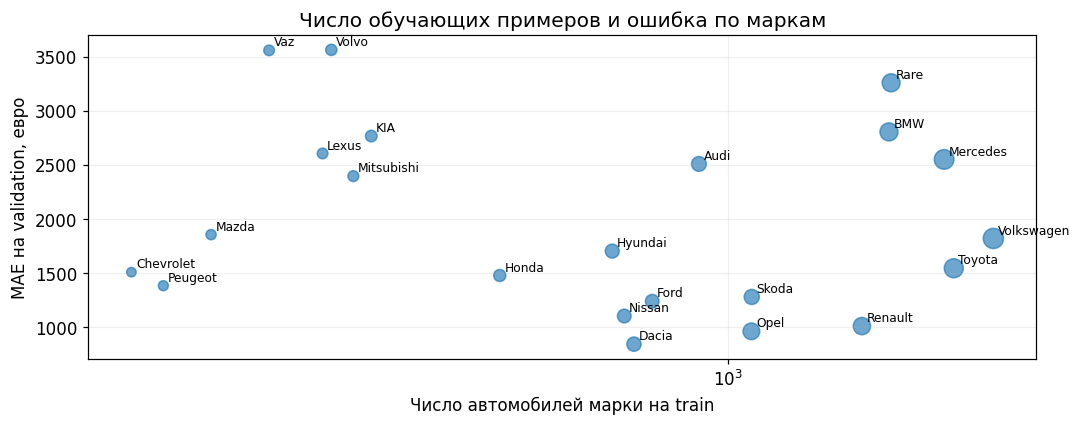

In [29]:
make_train_counts = X_train['Make'].value_counts()
errors['В train для марки'] = errors['Make'].map(make_train_counts).fillna(0).astype(int)
errors['Группа марки'] = np.select(
    [errors['В train для марки'].eq(0), errors['В train для марки'].lt(100)],
    ['Новая', 'Редкая (<100)'], default='Частая (≥100)'
)
errors['Относительная ошибка, %'] = 100 * errors['Абсолютная ошибка'] / errors['Цена']
by_make = errors.groupby('Make').agg(
    n_train=('В train для марки', 'first'), n_valid=('Цена', 'size'),
    MAE=('Абсолютная ошибка', 'mean'), median_price=('Цена', 'median'),
    median_APE=('Относительная ошибка, %', 'median')
)
display(by_make.sort_values('n_train').round(1))
display(errors.groupby('Группа марки').agg(
    n=('Цена', 'size'), MAE=('Абсолютная ошибка', 'mean'),
    median_price=('Цена', 'median'), median_APE=('Относительная ошибка, %', 'median')
).round(1))

fig, ax = plt.subplots(figsize=(10, 4))
ax.scatter(by_make['n_train'], by_make['MAE'], s=25 + 150 * by_make['n_valid'] / by_make['n_valid'].max(), alpha=.65)
for brand, row in by_make.iterrows():
    ax.annotate(brand, (row['n_train'], row['MAE']), fontsize=8, xytext=(3, 3), textcoords='offset points')
ax.set_xscale('symlog', linthresh=1)
ax.set(title='Число обучающих примеров и ошибка по маркам', xlabel='Число автомобилей марки на train', ylabel='MAE на validation, евро')
ax.grid(alpha=.2)
plt.tight_layout()
plt.show()

**Что сказать по результату?** Назовите две марки с большой ошибкой. Проверьте, сколько у них обучающих и проверочных строк и какова типичная цена. По одному графику нельзя заключить, что дополнительное число строк обязательно уменьшит ошибку: состав автомобилей тоже различается.

### 9.3. Одна общая модель или две по типу коробки?
У отдельных моделей могут быть разные зависимости цены от возраста и пробега. Но каждой достаётся меньше данных. Проверим обе стороны на одинаковом алгоритме — Ridge с OHE. Для сравнения используем ровно те же строки validation.

In [30]:
global_ridge = Pipeline([('prepare', clone(preprocessor)), ('model', Ridge(alpha=10, solver='lsqr'))])
global_ridge.fit(X_train, y_train)
global_pred = pd.Series(global_ridge.predict(X_valid), index=X_valid.index)
segment_pred = global_pred.copy()  # резервный прогноз для не встречавшихся сегментов
segment_models = {}
for transmission in X_train['Transmission'].dropna().unique():
    fit_mask = X_train['Transmission'].eq(transmission)
    valid_mask = X_valid['Transmission'].eq(transmission)
    model = clone(global_ridge).fit(X_train.loc[fit_mask], y_train.loc[fit_mask])
    segment_models[transmission] = model
    if valid_mask.any():
        segment_pred.loc[valid_mask] = model.predict(X_valid.loc[valid_mask])

segment_rows = []
for segment in ['Все'] + list(X_train['Transmission'].dropna().unique()):
    mask = pd.Series(True, index=X_valid.index) if segment == 'Все' else X_valid['Transmission'].eq(segment)
    for name, prediction in [('Общая модель', global_pred), ('Отдельные модели', segment_pred)]:
        segment_rows.append({'Сегмент': segment, 'Подход': name, 'Строк': int(mask.sum()),
                             **metrics(y_valid.loc[mask], prediction.loc[mask])})
display(pd.DataFrame(segment_rows).round(3))

,Сегмент,Подход,Строк,"MAE, евро","RMSE, евро",R²
0,Все,Общая модель,6413,3528.087,6830.243,0.550
1,Все,Отдельные модели,6413,2977.440,6264.146,0.622
2,Automatic,Общая модель,2915,4547.365,8324.958,0.526
3,Automatic,Отдельные модели,2915,4634.997,7906.821,0.573
4,Manual,Общая модель,3498,2678.689,5270.196,-0.041
5,Manual,Отдельные модели,3498,1596.142,4454.318,0.256


Сравните выигрыш и проигрыш внутри каждого сегмента. Общая модель тоже умеет учитывать коробку через OHE, но без взаимодействий её числовые коэффициенты общие. Отдельные модели снимают это ограничение ценой уменьшения обучающих выборок. Позже добавим взаимодействия в одну линейную модель.

## 10. Бонус: градиентный бустинг
Random Forest усредняет деревья, обученные на разных подвыборках. В градиентном бустинге деревья добавляются последовательно: новое дерево корректирует ошибки текущего ансамбля. Для квадратичной функции потерь направление коррекции связано с остатками.

`learning_rate` регулирует силу каждого шага, `n_estimators` — число деревьев. Слишком сложные деревья и слишком много шагов могут привести к переобучению.

### 10.1. LightGBM: сначала числа, затем все категории
Сначала используем уже знакомую обработку OHE: сравнение относится к одной и той же схеме данных. LightGBM также поддерживает собственную обработку категорий, но здесь оставляем её за рамками основного эксперимента.

In [31]:
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor
import lightgbm, catboost
print('LightGBM:', lightgbm.__version__, 'CatBoost:', catboost.__version__)

lgbm_parameters = dict(n_estimators=400, learning_rate=.05, num_leaves=31,
                       min_child_samples=30, random_state=42, n_jobs=2, verbosity=-1)
lgbm_numeric = Pipeline([
    ('prepare', ColumnTransformer([('num', clone(numeric_processing), NUMERIC_FEATURES)])),
    ('model', LGBMRegressor(**lgbm_parameters))
])
lgbm_ohe = Pipeline([
    ('prepare', clone(preprocessor)), ('model', LGBMRegressor(**lgbm_parameters))
])
evaluate('LightGBM: числа', lgbm_numeric)
evaluate('LightGBM: OHE', lgbm_ohe)
display(pd.DataFrame(validation_rows).set_index('Модель').round(3))

LightGBM: 4.7.0 CatBoost: 1.2.10


,"MAE, евро","RMSE, евро",R²,"Обучение, с"
Модель,,,,
LR: числа,4307.775,7685.150,0.431,0.015
LR: числа + map трансмиссии,4177.205,7584.741,0.446,0.018
LR: OHE,3543.912,6851.410,0.548,0.117
RF: числа,2684.941,5722.625,0.684,1.394
RF: OHE,2037.646,5047.769,0.754,12.356
LR: Target Encoding,3782.384,7011.329,0.526,0.039
RF: Target Encoding,1942.872,4879.855,0.771,2.840
LightGBM: числа,2631.877,5585.017,0.699,0.294
LightGBM: OHE,2041.384,4983.966,0.761,0.473


### 10.2. Небольшая настройка LightGBM
- `num_leaves`: сколько листьев может быть у дерева; больше — сложнее зависимость.
- `min_child_samples`: минимальное число строк в листе; больше — осторожнее подгонка к небольшим группам.
- `n_estimators`: число шагов бустинга.
- `reg_lambda`: регуляризация весов листьев.

Проверим шесть комбинаций на трёх разбиениях train. Также проверим порог редкости, включая отсутствие объединения: в упражнении оно дало меньшую CV-ошибку для Ridge, но для бустинга проверяем заново. Передаём в поиск весь Pipeline, чтобы OHE обучался внутри каждого разбиения. Validation не участвует в этом поиске, test по-прежнему закрыт.

In [32]:
lgbm_search = RandomizedSearchCV(
    clone(lgbm_ohe),
    param_distributions={
        'model__num_leaves': [15, 31, 63],
        'model__min_child_samples': [20, 60],
        'model__n_estimators': [400, 700],
        'model__reg_lambda': [0, 5],
        'prepare__cat__encode__min_frequency': [None, 5, 20]
    }, n_iter=6, scoring='neg_mean_absolute_error', cv=cv,
    random_state=42, n_jobs=1, refit=True
)
lgbm_search.fit(X_train, y_train)
print('Выбранные параметры:', lgbm_search.best_params_)
print('CV MAE:', -lgbm_search.best_score_)
lgbm_tuned = lgbm_search.best_estimator_
evaluate('LightGBM: подбор', lgbm_tuned)
search_table = pd.DataFrame(lgbm_search.cv_results_)
display(search_table[['params', 'mean_test_score', 'std_test_score']]
        .assign(MAE=lambda t: -t['mean_test_score']).sort_values('MAE').drop(columns='mean_test_score'))

Выбранные параметры: {'prepare__cat__encode__min_frequency': 5, 'model__reg_lambda': 5, 'model__num_leaves': 31, 'model__n_estimators': 700, 'model__min_child_samples': 20}
CV MAE: 2123.485179359913


,params,std_test_score,MAE
4,"{'prepare__cat__encode__min_frequency': 5, 'mo...",57.587865,2123.485179
2,"{'prepare__cat__encode__min_frequency': None, ...",40.730981,2127.481270
3,"{'prepare__cat__encode__min_frequency': None, ...",44.570600,2152.061601
0,"{'prepare__cat__encode__min_frequency': 5, 'mo...",49.248469,2157.025486
5,"{'prepare__cat__encode__min_frequency': 20, 'm...",63.874200,2160.925214
1,"{'prepare__cat__encode__min_frequency': 20, 'm...",62.117982,2172.895830


### 10.3. CatBoost: зачем отдельная библиотека для категорий?
CatBoost принимает исходные категории и строит их представления внутри алгоритма. Для части признаков может использовать OHE, для других — статистики по целевой переменной с механизмами, уменьшающими утечку при обучении. Это не простой `.groupby().mean()` по всей таблице.

Передаём имена категориальных столбцов через `cat_features`. Числовые пропуски можно оставить, категориальные заменяем строковым маркером. Число итераций выбирается ранней остановкой по validation: поэтому результат на ней используется для выбора, а итог проверяется на test.

In [33]:
def catboost_frame(frame):
    result = frame[FEATURES].copy()
    for col in CATEGORY_FEATURES:
        result[col] = result[col].fillna('Пропуск').astype(str)
    return result

cat_model = CatBoostRegressor(
    iterations=1200, depth=7, learning_rate=.05,
    loss_function='RMSE', eval_metric='MAE', cat_features=CATEGORY_FEATURES,
    random_seed=42, thread_count=2, verbose=False, allow_writing_files=False
)
start = perf_counter()
cat_model.fit(catboost_frame(X_train), y_train,
              eval_set=(catboost_frame(X_valid), y_valid),
              early_stopping_rounds=100, verbose=False)
cat_seconds = perf_counter() - start
cat_valid_prediction = cat_model.predict(catboost_frame(X_valid))
validation_rows.append({'Модель': 'CatBoost', **metrics(y_valid, cat_valid_prediction),
                        'Обучение, с': cat_seconds})
print('Число сохранённых деревьев:', cat_model.tree_count_)
display(pd.DataFrame(validation_rows).set_index('Модель').sort_values('MAE, евро').round(3))

Число сохранённых деревьев: 1199


,"MAE, евро","RMSE, евро",R²,"Обучение, с"
Модель,,,,
RF: Target Encoding,1942.872,4879.855,0.771,2.840
CatBoost,1956.914,4888.489,0.770,15.537
LightGBM: подбор,2027.889,4967.694,0.762,0.797
RF: OHE,2037.646,5047.769,0.754,12.356
LightGBM: OHE,2041.384,4983.966,0.761,0.473
LightGBM: числа,2631.877,5585.017,0.699,0.294
RF: числа,2684.941,5722.625,0.684,1.394
LR: OHE,3543.912,6851.410,0.548,0.117
LR: Target Encoding,3782.384,7011.329,0.526,0.039


## 11. Бонус: улучшаем линейную модель до сравнения с бустингами
У бустинга уже есть возможность находить нелинейные зависимости и сочетания условий. У исходной LR связь с годом или пробегом — прямая. Теперь последовательно изменим постановку и признаки.

**План:** логарифм цены → регуляризация → нелинейные функции числовых признаков → взаимодействия с категориями. Каждый шаг сравниваем с предыдущим. MAE и RMSE считаем в евро после обратного преобразования.

### 11.1. Логарифм цены
При переходе от 5 до 10 тысяч и от 10 до 20 тысяч цена удваивается. В логарифмической шкале это одинаковое изменение. Очень дорогие автомобили меньше доминируют в квадратичной ошибке.

`TransformedTargetRegressor` обучает внутреннюю модель на `log1p(y)` и возвращает прогноз через `expm1`. Это меняет оптимизируемую ошибку, а не только подписи графика. Обратное преобразование среднего логарифма не равно среднему цены, поэтому результат по MAE и RMSE проверяем отдельно.

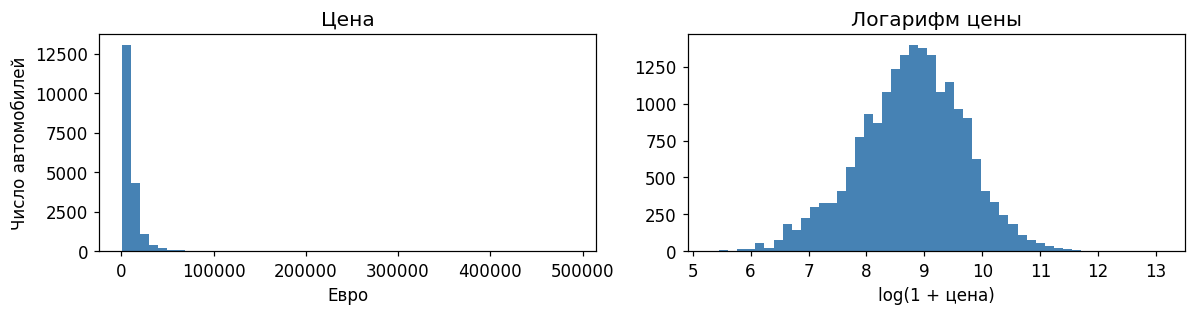

,"MAE, евро","RMSE, евро",R²,"Обучение, с"
Модель,,,,
LR: OHE,3543.912,6851.410,0.548,0.117
LR: OHE + log цены,2371.165,6011.205,0.652,0.119


In [34]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3))
axes[0].hist(y_train, bins=50, color='steelblue')
axes[0].set(title='Цена', xlabel='Евро', ylabel='Число автомобилей')
axes[1].hist(np.log1p(y_train), bins=50, color='steelblue')
axes[1].set(title='Логарифм цены', xlabel='log(1 + цена)')
plt.tight_layout()
plt.show()

lr_log = TransformedTargetRegressor(
    regressor=Pipeline([('prepare', clone(preprocessor)), ('model', LinearRegression())]),
    func=np.log1p, inverse_func=np.expm1
)
evaluate('LR: OHE + log цены', lr_log)
display(pd.DataFrame(validation_rows).set_index('Модель').loc[
    ['LR: OHE', 'LR: OHE + log цены']].round(3))

### 11.2. Ridge: ограничиваем большие веса
Ridge добавляет штраф за сумму квадратов коэффициентов. Это помогает, когда признаков много, они коррелируют или некоторые категории редки. `alpha` задаёт силу штрафа: слишком большой штраф может ухудшить прогноз.

Сначала Ridge для исходной цены, затем Ridge для логарифма цены. Подбираем `alpha` по CV MAE **в евро**. Одинаковый набор проверяемых значений делает шаги сопоставимыми.

In [35]:
ridge_search = GridSearchCV(
    Pipeline([('prepare', clone(preprocessor)), ('model', Ridge(solver='lsqr', tol=1e-6))]),
    {'model__alpha': [.1, 1, 10, 100]},
    scoring='neg_mean_absolute_error', cv=cv, n_jobs=1
)
ridge_search.fit(X_train, y_train)
ridge_raw = ridge_search.best_estimator_
evaluate('Ridge: OHE', ridge_raw)

ridge_log_search = GridSearchCV(
    TransformedTargetRegressor(
        regressor=Pipeline([('prepare', clone(preprocessor)), ('model', Ridge(solver='lsqr', tol=1e-6))]),
        func=np.log1p, inverse_func=np.expm1
    ),
    {'regressor__model__alpha': [.1, 1, 10, 100]},
    scoring='neg_mean_absolute_error', cv=cv, n_jobs=1
)
ridge_log_search.fit(X_train, y_train)
ridge_log = ridge_log_search.best_estimator_
evaluate('Ridge: OHE + log цены', ridge_log)
print('Ridge:', ridge_search.best_params_)
print('Ridge + log:', ridge_log_search.best_params_)

Ridge: {'model__alpha': 1}
Ridge + log: {'regressor__model__alpha': 1}


### 11.3. Нелинейность в признаках: сплайны
Цена может быстро падать при небольшом пробеге и медленнее — при большом. Вместо одной прямой используем несколько гладких функций каждого числового признака. Линейная модель подбирает веса этих функций: **линейность по весам сохраняется**, зависимость от исходного признака становится нелинейной.

`SplineTransformer` обучает расположение узлов только по train. Используем 6 узлов и линейное продолжение за диапазоном обучающих значений. Это не гарантирует разумной экстраполяции далеко за пределы данных.

In [36]:
spline_processing = Pipeline([
    ('fill', SimpleImputer(strategy='median')),
    ('spline', SplineTransformer(n_knots=6, degree=3, include_bias=False,
                                 extrapolation='linear')),
    ('scale', StandardScaler())
])
spline_preprocessor = ColumnTransformer([
    ('num', spline_processing, NUMERIC_FEATURES),
    ('cat', clone(categorical_processing), CATEGORY_FEATURES)
], sparse_threshold=1.0)
spline_search = GridSearchCV(
    TransformedTargetRegressor(
        regressor=Pipeline([('prepare', spline_preprocessor), ('model', Ridge(solver='lsqr', tol=1e-6))]),
        func=np.log1p, inverse_func=np.expm1
    ),
    {'regressor__model__alpha': [.1, 1, 10, 100]},
    scoring='neg_mean_absolute_error', cv=cv, n_jobs=1
)
spline_search.fit(X_train, y_train)
ridge_spline = spline_search.best_estimator_
evaluate('Ridge: log + сплайны', ridge_spline)
print(spline_search.best_params_)

{'regressor__model__alpha': 10}


### 11.4. Взаимодействие: разная зависимость от возраста для разных марок
Сначала небольшой самостоятельный пример на трёх наиболее представленных марках. Обычный OHE позволяет сдвигать прямую вверх или вниз для каждой марки, но коэффициент возраста остаётся общим.

Признак `возраст × индикатор марки` равен возрасту для этой марки и нулю для остальных. Его коэффициент добавляет **собственное изменение цены за год**. При добавлении таких признаков линии могут иметь разные наклоны.

Возраст считаем относительно фиксированного года, восстановленного из исходных `Year + Age`, а не сегодняшней даты. График иллюстрирует устройство модели с двумя признаками; это не причинная оценка обесценивания.

Отрицательные цены на части прямых — недостаток этого упрощённого примера без остальных признаков. Здесь показываем различие наклонов; для полноценного прогноза выше используем все признаки и логарифм цены.

Год отсчёта возраста: 2022


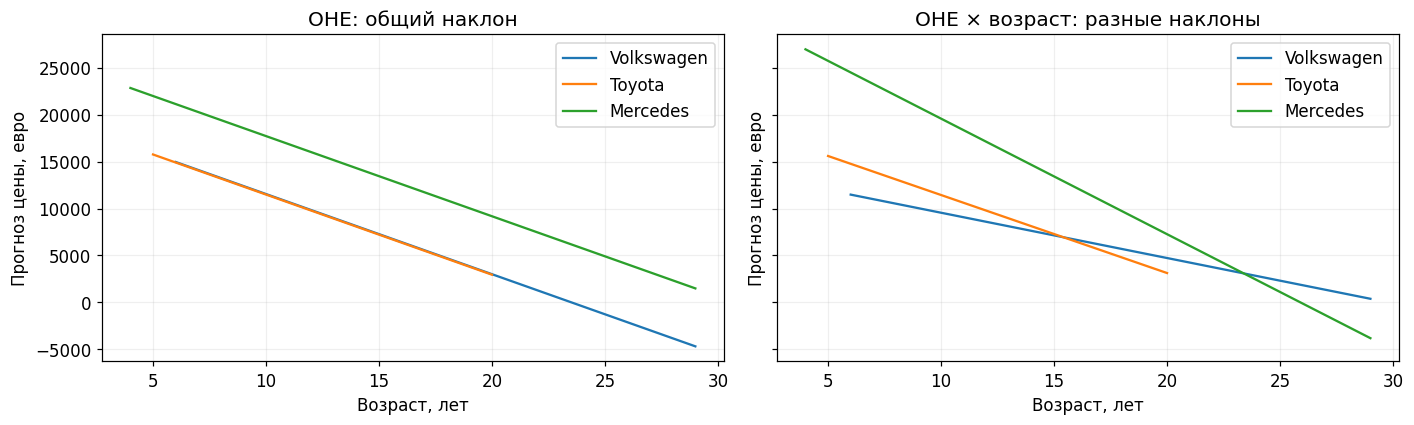

In [37]:
REFERENCE_YEAR = int((df['Year'] + df['Age']).mode().iloc[0]) if 'Age' in df else int(X_train['Year'].max())
print('Год отсчёта возраста:', REFERENCE_YEAR)
top3 = X_train['Make'].value_counts().head(3).index.tolist()
mask3 = X_train['Make'].isin(top3)
three_brands = X_train.loc[mask3, ['Make', 'Year']].copy()
three_brands['Age'] = REFERENCE_YEAR - three_brands['Year']
brand_ohe = OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore')
brand_indicators = brand_ohe.fit_transform(three_brands[['Make']])
age = three_brands['Age'].to_numpy().reshape(-1, 1)
plain_design = np.column_stack([age, brand_indicators])
interaction_design = np.column_stack([age, brand_indicators, age * brand_indicators])
plain_demo = LinearRegression().fit(plain_design, y_train.loc[mask3])
interaction_demo = LinearRegression().fit(interaction_design, y_train.loc[mask3])

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for brand in top3:
    subset = three_brands[three_brands['Make'].eq(brand)]
    grid = np.linspace(subset['Age'].quantile(.05), subset['Age'].quantile(.95), 80)
    indicators = brand_ohe.transform(pd.DataFrame({'Make': [brand] * len(grid)}))
    design = np.column_stack([grid, indicators])
    with_interaction = np.column_stack([design, grid[:, None] * indicators])
    axes[0].plot(grid, plain_demo.predict(design), label=brand)
    axes[1].plot(grid, interaction_demo.predict(with_interaction), label=brand)
for ax, title in zip(axes, ['OHE: общий наклон', 'OHE × возраст: разные наклоны']):
    ax.set(title=title, xlabel='Возраст, лет', ylabel='Прогноз цены, евро')
    ax.legend()
    ax.grid(alpha=.2)
plt.tight_layout()
plt.show()

### 11.5. Добавляем взаимодействия в полную модель
Сохраняем все исходные признаки и добавляем:
- **марка × возраст:** разные наклоны;
- **марка + модель:** одно название модели у разных марок не обязано означать одно и то же;
- **марка + пятилетний период выпуска:** отдельные поправки для поколений автомобилей.

В произведении `Age × Make` используем полный набор индикаторов; Ridge допускает зависимые признаки и ограничивает веса. Конструктор ниже нужен, чтобы OHE обучался внутри каждого CV-разбиения. Детерминированные комбинации столбцов не используют цены.

In [38]:
from sklearn.base import BaseEstimator, TransformerMixin

class BrandAgeInteraction(BaseEstimator, TransformerMixin):
    def __init__(self, reference_year=2022, min_frequency=20):
        self.reference_year = reference_year
        self.min_frequency = min_frequency

    def fit(self, X, y=None):
        self.encoder_ = OneHotEncoder(min_frequency=self.min_frequency,
                                      handle_unknown='infrequent_if_exist', sparse_output=True)
        self.encoder_.fit(X[['Make']].fillna('Пропуск'))
        age = self.reference_year - X['Year'].to_numpy()
        self.age_scale_ = max(float(np.std(age)), 1.0)
        return self

    def transform(self, X):
        indicators = self.encoder_.transform(X[['Make']].fillna('Пропуск'))
        age = (self.reference_year - X['Year'].to_numpy()) / self.age_scale_
        return indicators.multiply(age[:, None]).tocsr()


def add_interactions(frame):
    result = frame.copy()
    result['Make_Model'] = result['Make'].fillna('Пропуск') + ' / ' + result['Model'].fillna('Пропуск')
    result['Make_Period'] = result['Make'].fillna('Пропуск') + ' / ' + (result['Year'] // 5 * 5).astype(str)
    return result

advanced_categories = CATEGORY_FEATURES + ['Make_Model', 'Make_Period']
advanced_preprocessor = ColumnTransformer([
    ('num', clone(spline_processing), NUMERIC_FEATURES),
    ('cat', clone(categorical_processing), advanced_categories),
    ('brand_age', BrandAgeInteraction(reference_year=REFERENCE_YEAR), ['Make', 'Year'])
], sparse_threshold=1.0)
advanced_pipeline = Pipeline([
    ('features', FunctionTransformer(add_interactions)),
    ('prepare', advanced_preprocessor),
    ('model', Ridge(solver='lsqr', tol=1e-6))
])
advanced_search = GridSearchCV(
    TransformedTargetRegressor(regressor=advanced_pipeline, func=np.log1p, inverse_func=np.expm1),
    {'regressor__model__alpha': [.1, 1, 10, 100],
     'regressor__prepare__cat__encode__min_frequency': [None, 5, 20]},
    scoring='neg_mean_absolute_error', cv=cv, n_jobs=1
)
advanced_search.fit(X_train, y_train)
ridge_advanced = advanced_search.best_estimator_
evaluate('Ridge: log + сплайны + взаимодействия', ridge_advanced)
print('Параметры:', advanced_search.best_params_)

Параметры: {'regressor__model__alpha': 1, 'regressor__prepare__cat__encode__min_frequency': None}


### 11.6. Получилось ли приблизиться к бустингу?
Сравниваем заранее заданную последовательность. Улучшение не обязано быть монотонным: новый признак может добавить шум. «Не хуже» всегда относится к конкретной метрике и конкретной проверочной части.

Линейная модель: Ridge: log + сплайны + взаимодействия
Бустинг: CatBoost
Разница MAE (линейная − бустинг): -43.1 евро
Линейная лучше или равна по MAE.


,"MAE, евро","RMSE, евро",R²,"Обучение, с"
Модель,,,,
LR: OHE,3543.912,6851.410,0.548,0.117
LR: OHE + log цены,2371.165,6011.205,0.652,0.119
Ridge: OHE,3535.784,6840.054,0.549,0.132
Ridge: OHE + log цены,2369.083,6012.966,0.652,0.131
Ridge: log + сплайны,2223.836,5586.417,0.699,0.266
Ridge: log + сплайны + взаимодействия,1913.766,5056.219,0.754,0.599
LightGBM: подбор,2027.889,4967.694,0.762,0.797
CatBoost,1956.914,4888.489,0.770,15.537


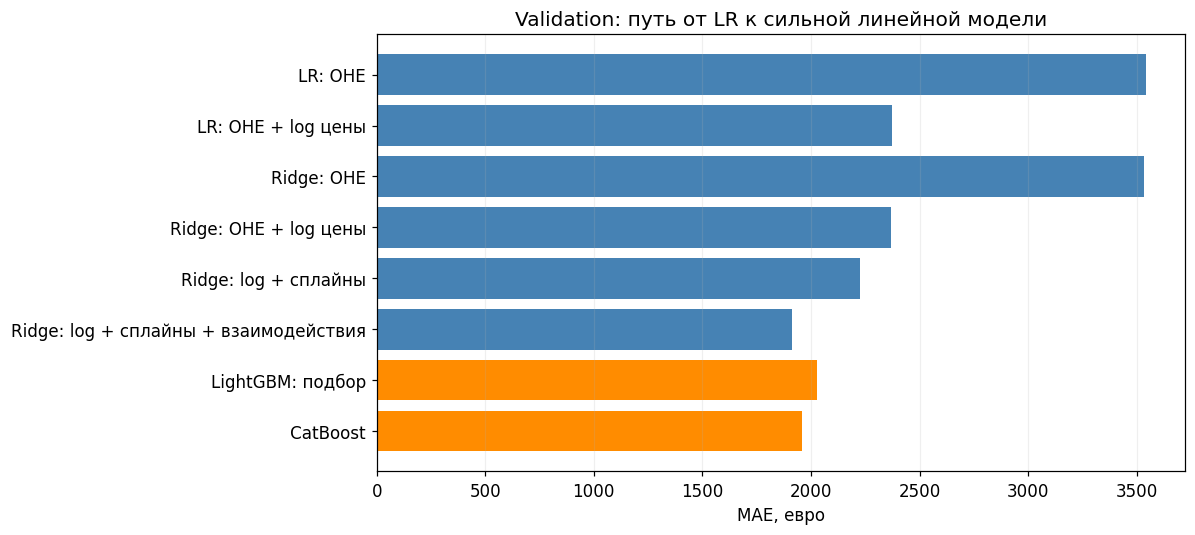

In [39]:
linear_names = ['LR: OHE', 'LR: OHE + log цены', 'Ridge: OHE', 'Ridge: OHE + log цены',
                'Ridge: log + сплайны', 'Ridge: log + сплайны + взаимодействия']
boost_names = ['LightGBM: подбор', 'CatBoost']
all_valid = pd.DataFrame(validation_rows).set_index('Модель')
comparison_final = all_valid.loc[linear_names + boost_names]
display(comparison_final.round(3))
fig, ax = plt.subplots(figsize=(11, 5))
colors = ['darkorange' if name in boost_names else 'steelblue' for name in comparison_final.index]
ax.barh(comparison_final.index, comparison_final['MAE, евро'], color=colors)
ax.invert_yaxis()
ax.set(title='Validation: путь от LR к сильной линейной модели', xlabel='MAE, евро')
ax.grid(axis='x', alpha=.2)
plt.tight_layout()
plt.show()

best_linear_name = all_valid.loc[linear_names, 'MAE, евро'].idxmin()
best_boost_name = all_valid.loc[boost_names, 'MAE, евро'].idxmin()
gap = all_valid.loc[best_linear_name, 'MAE, евро'] - all_valid.loc[best_boost_name, 'MAE, евро']
print('Линейная модель:', best_linear_name)
print('Бустинг:', best_boost_name)
print(f'Разница MAE (линейная − бустинг): {gap:+.1f} евро')
print('Линейная лучше или равна по MAE.' if gap <= 0 else 'Бустинг лучше по MAE на указанную величину.')

### Тогда зачем нужны бустинги?
Линейная модель может дать сопоставимый или лучший результат после логарифмирования цены, регуляризации и подготовки подходящих признаков. Мы вручную задали формы зависимостей и взаимодействия.

Бустинг находит многие такие взаимодействия автоматически. Он удобен, когда зависимостей много и их трудно описать заранее. Цена удобства — свои параметры, вычислительные затраты и более сложная интерпретация. Линейный прогноз часто быстрее, но полный пайплайн со сплайнами и OHE тоже имеет стоимость.

В этой работе сравниваем конкретные настройки, а не доказываем превосходство целого класса моделей. Крупные промахи оцениваем отдельно по RMSE.

## 12. Итоговая проверка на test
Выборы уже сделаны по train/CV/validation. Переобучаем выбранную линейную модель и выбранный бустинг на объединении train + validation. У CatBoost фиксируем число деревьев, выбранное ранней остановкой; test не используем как `eval_set`.

Для контекста включаем исходную LR с OHE. На test выводим метрики **один раз** и не подбираем по ним новые параметры.

Небольшой разрыв на одном разбиении не доказывает устойчивого превосходства. Здесь проверяем достижимость сопоставимой ошибки на нашем наборе; для уверенного выбора понадобятся повторные проверки или новые данные.

In [40]:
X_development = pd.concat([X_train, X_valid])
y_development = pd.concat([y_train, y_valid])
final_baseline = clone(lr_ohe).fit(X_development, y_development)
final_linear = clone(fitted_models[best_linear_name]).fit(X_development, y_development)

if best_boost_name == 'CatBoost':
    final_boost = CatBoostRegressor(
        iterations=cat_model.tree_count_, depth=7, learning_rate=.05,
        loss_function='RMSE', cat_features=CATEGORY_FEATURES,
        random_seed=42, thread_count=2, verbose=False, allow_writing_files=False
    )
    final_boost.fit(catboost_frame(X_development), y_development)
    test_boost_prediction = final_boost.predict(catboost_frame(X_test))
else:
    final_boost = clone(lgbm_tuned).fit(X_development, y_development)
    test_boost_prediction = final_boost.predict(X_test)

test_predictions = {
    'Исходная LR + OHE': final_baseline.predict(X_test),
    best_linear_name: final_linear.predict(X_test),
    best_boost_name: test_boost_prediction
}
test_results = pd.DataFrame({name: metrics(y_test, prediction)
                             for name, prediction in test_predictions.items()}).T
display(test_results.round(3))
for metric in ['MAE, евро', 'RMSE, евро']:
    delta = test_results.loc[best_linear_name, metric] - test_results.loc[best_boost_name, metric]
    print(f'{metric}: линейная − бустинг = {delta:+.1f}')

MAE, евро: линейная − бустинг = -90.6
RMSE, евро: линейная − бустинг = -187.9


,"MAE, евро","RMSE, евро",R²
Исходная LR + OHE,3478.984,7027.595,0.545
Ridge: log + сплайны + взаимодействия,1940.178,5232.816,0.748
CatBoost,2030.798,5420.696,0.729


### 12.1. На каких автомобилях расходятся ошибки?
Не меняем модели после просмотра. Показываем остатки и группы цены для финалистов. Границы групп здесь заранее фиксированы в евро, а не подобраны по ошибкам.

,n,MAE_LR,MAE_boost
Ценовая группа,,,
до 5 тыс.,2435,935.5,1144.4
5–10 тыс.,2047,1409.4,1537.2
10–20 тыс.,1382,2151.7,2415.2
20–40 тыс.,430,4573.3,4351.0
свыше 40 тыс.,120,19509.2,15696.3


,Make,Model,Year,Distance,Цена,Прогноз LR,Прогноз бустинга,Разница ошибок
11868,Volkswagen,Touareg,2021,0.0,79999.0,29116.0,79062.0,49946.0
13802,Rare,Cayenne Coupe,2020,13500.0,107900.0,25757.0,66592.0,40834.0
23373,Audi,A8,2019,31000.0,85000.0,52843.0,84497.0,31654.0
15292,Mercedes,S Class,2018,51000.0,87000.0,49539.0,71682.0,22143.0
22795,Rare,Altele,2017,38000.0,45000.0,15336.0,53647.0,21017.0
7477,Rare,Range Rover,2018,29320.0,76000.0,48153.0,67383.0,19230.0
10388,Mercedes,S Class,2018,49000.0,69500.0,49547.0,71034.0,18419.0
6292,Audi,A8,2017,32935.0,67900.0,33790.0,50194.0,16405.0


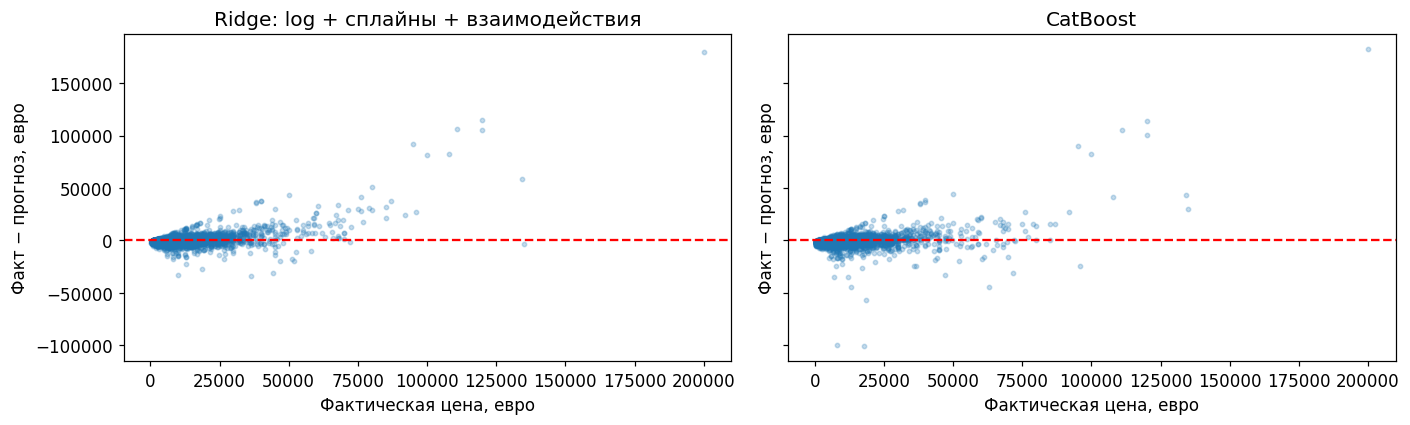

In [41]:
final_errors = X_test.copy()
final_errors['Цена'] = y_test
final_errors['Прогноз LR'] = test_predictions[best_linear_name]
final_errors['Прогноз бустинга'] = test_predictions[best_boost_name]
final_errors['Ошибка LR'] = abs(final_errors['Цена'] - final_errors['Прогноз LR'])
final_errors['Ошибка бустинга'] = abs(final_errors['Цена'] - final_errors['Прогноз бустинга'])
final_errors['Разница ошибок'] = final_errors['Ошибка LR'] - final_errors['Ошибка бустинга']
final_errors['Ценовая группа'] = pd.cut(final_errors['Цена'],
    bins=[0, 5000, 10000, 20000, 40000, np.inf],
    labels=['до 5 тыс.', '5–10 тыс.', '10–20 тыс.', '20–40 тыс.', 'свыше 40 тыс.'])
display(final_errors.groupby('Ценовая группа', observed=True).agg(
    n=('Цена', 'size'), MAE_LR=('Ошибка LR', 'mean'), MAE_boost=('Ошибка бустинга', 'mean')
).round(1))
display(final_errors.nlargest(8, 'Разница ошибок')[
    ['Make', 'Model', 'Year', 'Distance', 'Цена', 'Прогноз LR', 'Прогноз бустинга', 'Разница ошибок']
].round(0))

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharex=True, sharey=True)
for ax, name in zip(axes, [best_linear_name, best_boost_name]):
    prediction = test_predictions[name]
    ax.scatter(y_test, y_test - prediction, s=8, alpha=.25)
    ax.axhline(0, color='red', linestyle='--')
    ax.set(title=name, xlabel='Фактическая цена, евро', ylabel='Факт − прогноз, евро')
plt.tight_layout()
plt.show()

## 13. Коротко: приёмы из соревнований
1. **Согласовать валидацию с применением.** Если один автомобиль встречается несколько раз, объявления нужно группировать; для будущего рынка нужно временное разбиение по дате публикации. `Year` — год выпуска, не дата объявления. В нашем наборе нельзя достоверно восстановить эти группы и даты.
2. **Собирать осмысленные взаимодействия.** Уже проверили марку с возрастом и периодом выпуска.
3. **Считать групповые признаки без утечки.** Частоты — по train; статистики цены для обучающих строк — вне собственной части, как в Target Encoding.
4. **Усреднять разные модели.** Если они ошибаются по-разному, смесь может уменьшить ошибку. Вес выбирают на validation, не на test.

Ниже дополнительный опыт **только на validation**, без нового обращения к test. Возвращаемся к моделям, обученным только на train. Смешиваем уже выбранную линейную модель и бустинг. Это учебный поиск, результат не является дополнительной независимой оценкой.

In [42]:
linear_valid = fitted_models[best_linear_name].predict(X_valid)
boost_valid = cat_valid_prediction if best_boost_name == 'CatBoost' else lgbm_tuned.predict(X_valid)
blend_rows = []
for weight in np.linspace(0, 1, 11):
    prediction = weight * linear_valid + (1 - weight) * boost_valid
    blend_rows.append({'Вес линейной модели': weight, **metrics(y_valid, prediction)})
blend_results = pd.DataFrame(blend_rows)
display(blend_results.round(3))
best_weight = blend_results.loc[blend_results['MAE, евро'].idxmin(), 'Вес линейной модели']
print('Выбранный вес LR на validation:', best_weight)
print('0 — только бустинг; 1 — только линейная модель.')

Выбранный вес LR на validation: 0.6000000000000001
0 — только бустинг; 1 — только линейная модель.


,Вес линейной модели,"MAE, евро","RMSE, евро",R²
0,0.0,1956.914,4888.489,0.770
1,0.1,1920.651,4841.527,0.774
2,0.2,1891.684,4808.539,0.777
3,0.3,1870.288,4789.815,0.779
4,0.4,1856.518,4785.522,0.779
5,0.5,1849.569,4795.698,0.778
6,0.6,1848.431,4820.251,0.776
7,0.7,1854.371,4858.965,0.772
8,0.8,1867.153,4911.504,0.768
9,0.9,1886.896,4977.429,0.761


## 14. Что включить в отчёт
1. Словарь `.map()` и интерпретацию полученного веса трансмиссии.
2. Один узел дерева с категорией: условие и расшифровку кодов. Если таких узлов нет — сообщите это и объясните ограничение глубины 3.
3. Число столбцов OHE до и после объединения редких категорий; сравнение памяти sparse и плотного массива.
4. Таблицу эксперимента с порогом редкости и вывод.
5. Сравнение OHE и Target Encoding; объяснение, почему нужен `fit_transform` на train.
6. Ошибки по частым и редким маркам и результат сравнения общей и отдельных моделей.
7. Для бонуса: путь улучшения линейной модели, итоговые MAE/RMSE/R² и конкретные примеры оставшихся ошибок.

**Заключение в трёх предложениях:** какое преобразование помогло; какая модель лучше по выбранной метрике; какую информацию стоит собрать дополнительно (например, комплектацию, состояние или историю обслуживания).

### Документация
- [OneHotEncoder: редкие категории и sparse](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html)
- [TargetEncoder: сглаживание и внутренние разбиения](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.TargetEncoder.html)
- [ColumnTransformer](https://scikit-learn.org/stable/modules/generated/sklearn.compose.ColumnTransformer.html)
- [LightGBM: LGBMRegressor](https://lightgbm.readthedocs.io/en/stable/pythonapi/lightgbm.LGBMRegressor.html)
- [Категориальные признаки CatBoost](https://catboost.ai/docs/en/features/categorical-features)